In [1]:
import gpa as gpa
import datastruct as datastruct
import process as process

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
from scipy.stats import norm

In [74]:
length = 1023
freq = 4.0
center = 768
sigma = 40
strain = [0.00001 * freq, 0.0001 * freq, 0.001 * freq, 0.01 * freq] # Different level of deformation as a fraction of freq
noise = 0

data_2 = []
label_2_strain = ['0.001%', '0.01%', '0.1%', '1%']

for deformation in strain:
    data = datastruct.GPAData()
    data.sine = process.sine_1d(length, freq, deformation , noise)
    data.mask = process.mask_gaussian_1d(data.sine, center, sigma)
    data.phase_raw = gpa.phase_raw(data.sine, data.mask)
    data.phase = gpa.phase(data.sine, data.mask)
    data.gpa = gpa.gpa(data.sine, data.mask)
    data.strain = process.strain_1d(data.gpa, freq)
    data.error_gpa = process.error_gpa_1d(data.gpa, freq, deformation)
    data_2.append(data)

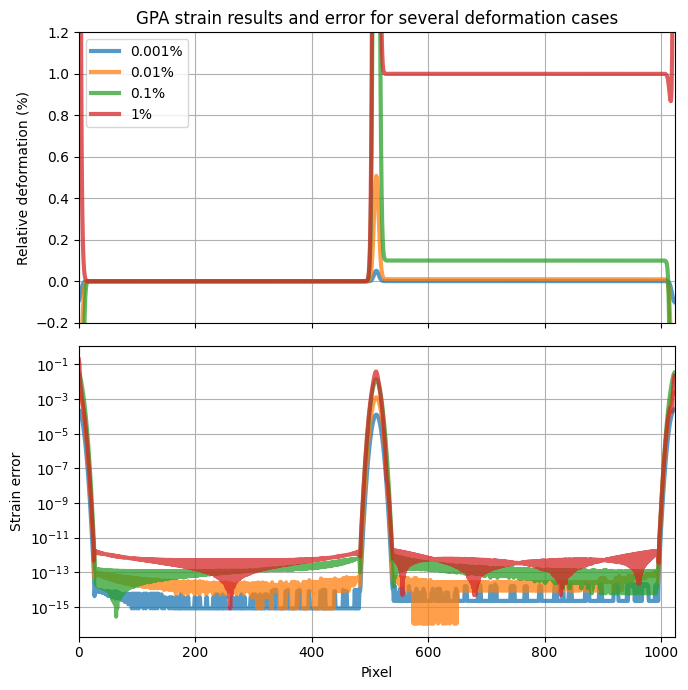

In [75]:
fig2, ax2 = plt.subplots(2, 1,figsize=(7, 7), sharex=True)
for i, data in enumerate(data_2):
    ax2[0].plot(100 * data.strain, linewidth=3, label=label_2_strain[i], alpha=0.75)
    ax2[1].plot(data.error_gpa, linewidth=3, label=label_2_strain[i], alpha=0.75)
    
ax2[0].set_title('GPA strain results and error for several deformation cases')
ax2[0].set_ylim(-0.2, 1.2) 
ax2[0].set_ylabel('Relative deformation (%)')
ax2[0].grid(visible=True)
ax2[0].legend()

ax2[1].set_xlim(0, 1024)
ax2[1].set_yscale('log')
ax2[1].set_ylabel('Strain error')
ax2[1].set_xlabel('Pixel')
ax2[1].grid(visible=True)

fig2.tight_layout()

plt.show()

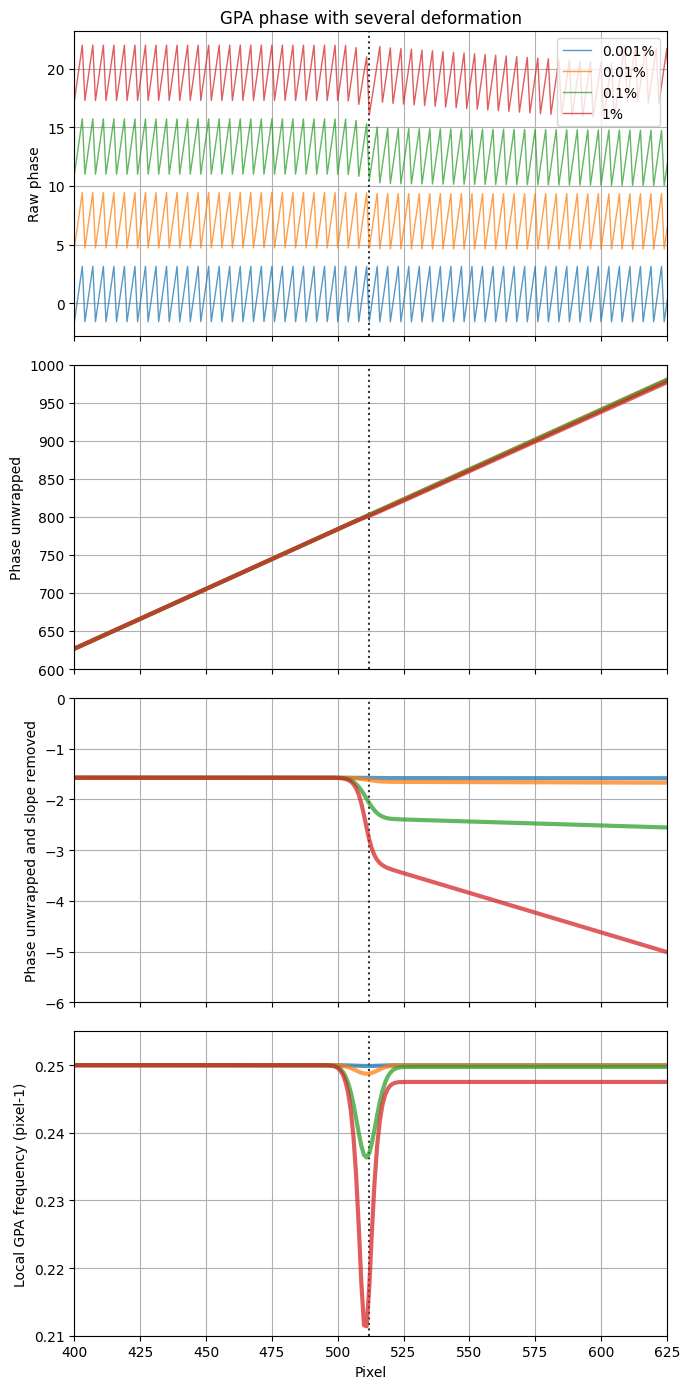

In [79]:
fig2_phase, ax2_phase = plt.subplots(4, 1,figsize=(7, 14), sharex=True)

shift_2 = [0, 2*np.pi, 4*np.pi, 6*np.pi]

for ax in ax2_phase:
    ax.axvline(x=512, color='black', linestyle=':', linewidth=1.5, alpha=0.8)

for i, data in enumerate(data_2):
    ax2_phase[0].plot(data.phase_raw + shift_2[i] , linewidth=1, label=label_2_strain[i], alpha=0.75)
    ax2_phase[1].plot(data.phase, linewidth=3, label=label_2_strain[i], alpha=0.75)
    ax2_phase[2].plot(data.phase - 2*np.pi*data_2[0].gpa[400] * np.linspace(0, 1023, 1024) , linewidth=3, label=label_2_strain[i], alpha=0.75)
    ax2_phase[3].plot(data.gpa, linewidth=3, label=label_2_strain[i], alpha=0.75)
    
ax2_phase[0].set_title('GPA phase with several deformation')
#ax2_phase[0].set_ylim(-0.2, 1.2) 
ax2_phase[0].set_ylabel('Raw phase')
ax2_phase[0].grid(visible=True)
ax2_phase[0].legend()

ax2_phase[1].set_xlim(400, 625)
#ax2_phase[1].set_yscale('log')
ax2_phase[1].set_ylim(600, 1000)
ax2_phase[1].set_ylabel('Phase unwrapped')
ax2_phase[1].grid(visible=True)

ax2_phase[2].set_ylim(-6, 0)
ax2_phase[2].set_ylabel('Phase unwrapped and slope removed')
ax2_phase[2].grid(visible=True)

ax2_phase[3].set_ylim(0.21, 0.255)
ax2_phase[3].set_ylabel('Local GPA frequency (pixel-1)')
ax2_phase[3].set_xlabel('Pixel')
ax2_phase[3].grid(visible=True)

fig2_phase.tight_layout()

plt.show()

0.24999999999999012
